# Calendar Data

## Data source

The calendar is an **external dataset that we build ourselves**. It is made of three parts:

- **Public holidays**: the Python package [`holidays`](https://pypi.org/project/holidays/), `holidays.US(state="IL")` (US federal + Illinois holidays).
- **Chicago Public Schools (CPS) breaks**: winter break and spring break, typed in by hand from the CPS academic calendars (**to double-check against the official CPS calendar of each year**).
- **Bridge days**: flags computed from the two parts above (eve of a holiday, long weekends, Thanksgiving week).

## Data description

One row per day, saved as `calendar.csv`:

- date
- year, month
- day_of_week (name), dow_n (0 = Monday), is_weekend
- is_holiday (any Illinois holiday), holiday_name
- is_major_holiday (New Year, Memorial Day, July 4, Labor Day, Thanksgiving, Christmas, with their "observed" days; **not** Juneteenth, Pulaski Day, Lincoln's Birthday, Columbus Day, which are ordinary working days for most people)
- is_christmas (own flag: Christmas is much quieter than the other holidays)
- is_holiday_eve (the working day just before a major holiday)
- is_long_weekend (the weekend days / bridge days of a 3+ day block around a holiday)
- is_thanksgiving_week (Monday to Sunday of Thanksgiving week)
- is_winter_break, is_spring_break (CPS)

## Objective

1. **Build the calendar** and check it (are the right days flagged?), then save it as an external-data table.
2. **Show that the calendar is relevant for the model.** For every calendar variable we check that trips on those days really differ, *consistently*, from comparable ordinary days. Only the variables that pass this check are used in the model of a "normal" day.
3. Compare nested models (with and without the calendar variables) to see how much each group of variables improves the description of normal activity.


In [1]:
import os, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy import stats
from statsmodels.stats.multitest import multipletests
import statsmodels.formula.api as smf

try:
    import holidays
except ImportError:
    %pip install holidays
    import holidays

%matplotlib inline
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)
sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore")

### Settings

In [ ]:
START, END = "2022-01-01", "2025-12-31"      # study period
BUFFER_DAYS = 45                              # the calendar is built a bit beyond the study period: the flag of 31 Dec depends on 1 Jan
SAVE_FOLDER = "./clean/"                      
os.makedirs(SAVE_FOLDER, exist_ok=True)

# the daily trips file is searched in these places (the first one that exists is used)
CITY_CANDIDATES = ["../daily_counts_city.csv", "data/daily_counts_city.csv", "daily_counts_city.csv",
                   "../data/daily_counts_city.csv", "./raw/daily_counts_city.csv"]
CITY_PATH = next((p for p in CITY_CANDIDATES if os.path.exists(p)), None)
print("daily trips file:", CITY_PATH)

daily trips file: data/daily_counts_city.csv


# Building the calendar

### Step 1: which holidays does the package know?
We list every Illinois holiday of the study period. We will keep only the ones that change how people ride.

In [3]:
il = holidays.US(state="IL", years=range(pd.Timestamp(START).year - 1, pd.Timestamp(END).year + 2))
il_table = (pd.Series(il, name="holiday").rename_axis("date").reset_index()
              .assign(date=lambda d: pd.to_datetime(d.date)).sort_values("date"))
il_table = il_table[(il_table.date >= START) & (il_table.date <= END)]
il_table["weekday"] = il_table.date.dt.day_name()
il_table

,date,holiday,weekday
17,2022-01-01,New Year's Day,Saturday
26,2022-01-17,Martin Luther King Jr. Day,Monday
31,2022-02-11,Lincoln's Birthday (observed),Friday
30,2022-02-12,Lincoln's Birthday,Saturday
27,2022-02-21,Washington's Birthday,Monday
32,2022-03-07,Casimir Pulaski Day,Monday
18,2022-05-30,Memorial Day,Monday
19,2022-06-19,Juneteenth National Independence Day,Sunday
20,2022-06-20,Juneteenth National Independence Day (observed),Monday
21,2022-07-04,Independence Day,Monday


### Step 2: holiday flags
`holidays` also lists the *observed* day when a holiday falls on a weekend (for example "New Year's Day (observed)"); we keep those, since people take the day off then.

"Independence" also matches *Juneteenth National Independence Day*, so Juneteenth is excluded on purpose.

In [5]:
MAJOR_KEYWORDS = ("New Year", "Memorial", "Independence", "Labor", "Thanksgiving", "Christmas")

def build_calendar(start, end):
    cal = pd.DataFrame({"date": pd.date_range(start, end, freq="D")})
    il = holidays.US(state="IL", years=range(cal.date.dt.year.min(), cal.date.dt.year.max() + 1))
    d = cal.date.dt.date
    cal["is_holiday"] = d.isin(il)
    cal["holiday_name"] = d.map(il).fillna("")
    cal["is_major_holiday"] = cal.holiday_name.apply(
        lambda n: any(k in n for k in MAJOR_KEYWORDS) and "Juneteenth" not in n)
    return cal

### Step 3: school breaks (Chicago Public Schools)
First and last day off of each break. **Check these dates against the official CPS calendar** (cps.edu): they are the only values typed by hand in this notebook.

In [6]:
SCHOOL_BREAKS = {
    "winter": [("2021-12-20", "2022-01-02"), ("2022-12-23", "2023-01-06"), ("2023-12-22", "2024-01-07"),
               ("2024-12-23", "2025-01-03"), ("2025-12-22", "2026-01-02")],
    "spring": [("2022-04-11", "2022-04-15"), ("2023-04-03", "2023-04-07"),
               ("2024-03-25", "2024-03-29"), ("2025-03-24", "2025-03-28")],
}

def add_school_breaks(cal):
    cal = cal.copy()
    for name, periods in SCHOOL_BREAKS.items():
        cal[f"is_{name}_break"] = False
        for s, e in periods:
            cal.loc[(cal.date >= s) & (cal.date <= e), f"is_{name}_break"] = True
    return cal

**Why only winter and spring break?** CPS has other non-school days (summer break, single non-attendance days, days off such as Pulaski Day or Columbus Day), but we only model the two long breaks of the school year, for three reasons:
- They are **multi-day blocks** (one to two weeks), so the change in the weekday commute and school runs is large enough to be measured and to appear several times in the data.
- **Summer break** is almost the same thing as the season, which the annual sine/cosine terms already capture, so a separate flag would be hard to tell apart from them.
- **Single days off**: Those that are public holidays are already covered by the holiday flags.


### Step 4: bridge days
- **Long weekend**: a block of 3 or more consecutive days off (weekend + holiday) that contains a holiday; we flag the non-holiday days of the block.
- **Holiday eve**: the working day just before a major holiday.
- **Thanksgiving week**: Monday to Sunday of the week of Thanksgiving.
- **Christmas**: its own flag (it behaves very differently from the other holidays, see the exploration below).

In [7]:
def add_holiday_context(cal):
    cal = cal.copy().sort_values("date").reset_index(drop=True)
    is_off = cal.is_major_holiday | (cal.date.dt.dayofweek >= 5)
    block = (is_off != is_off.shift()).cumsum()
    block_len = is_off.groupby(block).transform("sum")
    has_hol = cal.is_major_holiday.groupby(block).transform("any")
    cal["is_long_weekend"] = is_off & (block_len >= 3) & has_hol & ~cal.is_major_holiday
    cal["is_holiday_eve"] = cal.is_major_holiday.shift(-1, fill_value=False) & ~is_off
    tg = cal.loc[cal.holiday_name.str.contains("Thanksgiving") & ~cal.holiday_name.str.contains("After"), "date"]
    week_starts = set(tg - pd.to_timedelta(tg.dt.dayofweek, unit="D"))
    cal["is_thanksgiving_week"] = (cal.date - pd.to_timedelta(cal.date.dt.dayofweek, unit="D")).isin(week_starts)
    cal["is_christmas"] = cal.holiday_name.str.contains("Christmas")
    return cal

buffer = pd.Timedelta(days=BUFFER_DAYS)
calendar_full = add_holiday_context(add_school_breaks(build_calendar(pd.Timestamp(START) - buffer, pd.Timestamp(END) + buffer)))
print(f"Calendar built from {calendar_full.date.min().date()} to {calendar_full.date.max().date()} ({len(calendar_full)} days, including the buffer)")

Calendar built from 2021-11-17 to 2026-02-14 (1551 days, including the buffer)


### Sanity checks

In [8]:
# 1) one row per day, no gap, no duplicate
assert calendar_full.date.is_unique, "duplicated dates"
assert (calendar_full.date.diff().dropna() == pd.Timedelta(days=1)).all(), "gap in the dates"
print("OK: one row per day, no gap, no duplicate")

# 2) NA values
print("\nNA values per column:\n", calendar_full.isna().sum().loc[lambda s: s > 0] if calendar_full.isna().any().any() else "none")

OK: one row per day, no gap, no duplicate

NA values per column:
 none


In [9]:
# 3) known dates must carry the right flags
checks = [
    ("2022-07-04", "is_major_holiday", True,  "July 4th 2022"),
    ("2023-05-29", "is_major_holiday", True,  "Memorial Day 2023"),
    ("2025-09-01", "is_major_holiday", True,  "Labor Day 2025"),
    ("2024-11-28", "is_major_holiday", True,  "Thanksgiving 2024"),
    ("2023-12-25", "is_christmas",     True,  "Christmas 2023"),
    ("2024-06-19", "is_holiday",       True,  "Juneteenth 2024 is a holiday..."),
    ("2024-06-19", "is_major_holiday", False, "...but not a major one"),
    ("2024-03-12", "is_holiday",       False, "ordinary Tuesday"),
    ("2024-03-27", "is_spring_break",  True,  "spring break 2024"),
    ("2024-04-10", "is_spring_break",  False, "after spring break 2024"),
    ("2023-12-27", "is_winter_break",  True,  "winter break 2023"),
    ("2024-11-27", "is_thanksgiving_week", True, "Wednesday of Thanksgiving week 2024"),
    ("2024-11-27", "is_holiday_eve",   True,  "eve of Thanksgiving 2024"),
]
cal_i = calendar_full.set_index("date")
rows = []
for day, col, expected, what in checks:
    got = bool(cal_i.loc[day, col])
    rows.append({"date": day, "check": what, "column": col, "expected": expected, "found": got, "ok": "OK" if got == expected else "PROBLEM"})
chk = pd.DataFrame(rows)
print(f"{(chk.ok == 'OK').sum()} / {len(chk)} checks passed")
chk

13 / 13 checks passed


,date,check,column,expected,found,ok
0,2022-07-04,July 4th 2022,is_major_holiday,True,True,OK
1,2023-05-29,Memorial Day 2023,is_major_holiday,True,True,OK
2,2025-09-01,Labor Day 2025,is_major_holiday,True,True,OK
3,2024-11-28,Thanksgiving 2024,is_major_holiday,True,True,OK
4,2023-12-25,Christmas 2023,is_christmas,True,True,OK
5,2024-06-19,Juneteenth 2024 is a holiday...,is_holiday,True,True,OK
6,2024-06-19,...but not a major one,is_major_holiday,False,False,OK
7,2024-03-12,ordinary Tuesday,is_holiday,False,False,OK
8,2024-03-27,spring break 2024,is_spring_break,True,True,OK
9,2024-04-10,after spring break 2024,is_spring_break,False,False,OK


In [10]:
# 4) how many flagged days per year? (a year with 0 of something is suspicious)
FLAGS = ["is_holiday", "is_major_holiday", "is_christmas", "is_holiday_eve", "is_long_weekend",
         "is_thanksgiving_week", "is_winter_break", "is_spring_break"]
in_study = calendar_full[(calendar_full.date >= START) & (calendar_full.date <= END)]
in_study.assign(year=in_study.date.dt.year).groupby("year")[FLAGS].sum()

,is_holiday,is_major_holiday,is_christmas,is_holiday_eve,is_long_weekend,is_thanksgiving_week,is_winter_break,is_spring_break
year,,,,,,,,
2022,17,7,2,1,9,7,11,5
2023,16,7,1,2,8,7,16,5
2024,14,6,1,4,4,7,16,5
2025,13,6,1,4,6,7,13,5


In [11]:
# 5) the major holidays of the study period, with the weekday they fall on
mh = in_study[in_study.is_major_holiday][["date", "holiday_name"]].assign(weekday=lambda d: d.date.dt.day_name())
mh

,date,holiday_name,weekday
45,2022-01-01,New Year's Day,Saturday
194,2022-05-30,Memorial Day,Monday
229,2022-07-04,Independence Day,Monday
292,2022-09-05,Labor Day,Monday
372,2022-11-24,Thanksgiving Day,Thursday
403,2022-12-25,Christmas Day,Sunday
404,2022-12-26,Christmas Day (observed),Monday
410,2023-01-01,New Year's Day,Sunday
411,2023-01-02,New Year's Day (observed),Monday
558,2023-05-29,Memorial Day,Monday


### Derived columns and saving
We add `year` and `month` columns for easy grouping, plus the weekday. The calendar is **clipped to the study period** before saving (the buffer was only needed to compute the flags correctly at the edges).

In [12]:
calendar = in_study.copy()
calendar["year"] = calendar.date.dt.year
calendar["month"] = calendar.date.dt.month
calendar["day_of_week"] = calendar.date.dt.day_name()
calendar["dow_n"] = calendar.date.dt.dayofweek
calendar["is_weekend"] = (calendar.dow_n >= 5)

ORDER = ["date", "year", "month", "day_of_week", "dow_n", "is_weekend", "is_holiday", "holiday_name",
         "is_major_holiday", "is_christmas", "is_holiday_eve", "is_long_weekend", "is_thanksgiving_week",
         "is_winter_break", "is_spring_break"]
calendar = calendar[ORDER].reset_index(drop=True)
calendar.to_csv(SAVE_FOLDER + "calendar.csv", index=False)
print(f"Saved {SAVE_FOLDER}calendar.csv: {len(calendar)} rows, {calendar.shape[1]} columns")
calendar.head()

Saved ./clean/calendar.csv: 1461 rows, 15 columns


,date,year,month,day_of_week,dow_n,is_weekend,is_holiday,holiday_name,is_major_holiday,is_christmas,is_holiday_eve,is_long_weekend,is_thanksgiving_week,is_winter_break,is_spring_break
0,2022-01-01,2022,1,Saturday,5,True,True,New Year's Day,True,False,False,False,False,True,False
1,2022-01-02,2022,1,Sunday,6,True,False,,False,False,False,True,False,True,False
2,2022-01-03,2022,1,Monday,0,False,False,,False,False,False,False,False,False,False
3,2022-01-04,2022,1,Tuesday,1,False,False,,False,False,False,False,False,False,False
4,2022-01-05,2022,1,Wednesday,2,False,False,,False,False,False,False,False,False,False


# Exploratory analysis

In [13]:
calendar = pd.read_csv(SAVE_FOLDER + "calendar.csv", parse_dates=["date"])
calendar.dtypes

date                    datetime64[ns]
year                             int64
month                            int64
day_of_week                     object
dow_n                            int64
is_weekend                        bool
is_holiday                        bool
holiday_name                    object
is_major_holiday                  bool
is_christmas                      bool
is_holiday_eve                    bool
is_long_weekend                   bool
is_thanksgiving_week              bool
is_winter_break                   bool
is_spring_break                   bool
dtype: object

### What does the calendar look like?
One row per year, one square per day. This is a visual check that the flags are where we expect them (holidays on the right dates, breaks in winter and spring, bridge days next to holidays).

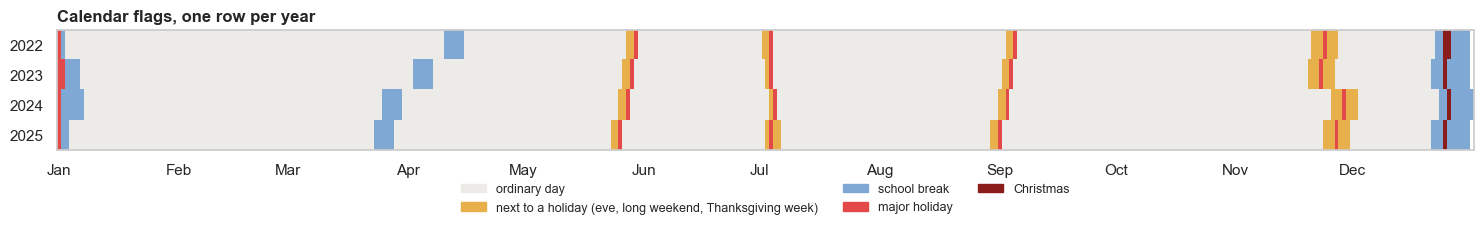

In [14]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

def day_category(df):
    cat = np.zeros(len(df), dtype=int)                       # 0 ordinary
    cat[(df.is_holiday_eve | df.is_long_weekend | df.is_thanksgiving_week).values] = 1   # next to a holiday
    cat[(df.is_winter_break | df.is_spring_break).values] = 2                          # school break
    cat[df.is_major_holiday.values] = 3                                                # major holiday
    cat[df.is_christmas.values] = 4                                                    # Christmas
    return cat

COLORS = ["#ecebe7", "#e8b04a", "#7fa8d4", "#e34948", "#8a1c1c"]
LABELS = ["ordinary day", "next to a holiday (eve, long weekend, Thanksgiving week)", "school break", "major holiday", "Christmas"]
years = sorted(calendar.year.unique())
grid = np.full((len(years), 366), np.nan)
for i, y in enumerate(years):
    d = calendar[calendar.year == y]
    grid[i, d.date.dt.dayofyear.values - 1] = day_category(d)

fig, ax = plt.subplots(figsize=(15, 2.6))
ax.imshow(grid, aspect="auto", cmap=ListedColormap(COLORS), vmin=-.5, vmax=4.5, interpolation="nearest")
ax.set_yticks(range(len(years))); ax.set_yticklabels(years)
month_starts = [pd.Timestamp(2023, m, 1).dayofyear - 1 for m in range(1, 13)]
ax.set_xticks(month_starts); ax.set_xticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.grid(False)
ax.legend(handles=[Patch(color=c, label=l) for c, l in zip(COLORS, LABELS)], ncol=3, loc="upper center",
          bbox_to_anchor=(.5, -.18), frameon=False, fontsize=9)
ax.set_title("Calendar flags, one row per year", loc="left", fontweight="bold")
plt.tight_layout(); plt.show()

In [15]:
# School breaks: length and number of weekdays (a spring break has no weekend day)
rows = []
for kind, periods in SCHOOL_BREAKS.items():
    for a, b in periods:
        d = calendar[(calendar.date >= a) & (calendar.date <= b)]
        rows.append({"break": kind, "first day": a, "last day": b, "days in study period": len(d), "weekdays": int((~d.is_weekend).sum())})
pd.DataFrame(rows)

,break,first day,last day,days in study period,weekdays
0,winter,2021-12-20,2022-01-02,2,0
1,winter,2022-12-23,2023-01-06,15,11
2,winter,2023-12-22,2024-01-07,17,11
3,winter,2024-12-23,2025-01-03,12,10
4,winter,2025-12-22,2026-01-02,10,8
5,spring,2022-04-11,2022-04-15,5,5
6,spring,2023-04-03,2023-04-07,5,5
7,spring,2024-03-25,2024-03-29,5,5
8,spring,2025-03-24,2025-03-28,5,5


### What could we do with this data?
- The calendar tells the model **which days are "normal" for a reason we already know**. Without it, every Christmas, every spring break and every long weekend would come out as an anomaly. With it, an anomaly means *something the calendar does not explain*.
- Calendar variables are known **in advance**: they can be used for any future day without a forecast.
- All the external tables (calendar, weather, spatial grid) share the same key (`date`), so they can be merged with the trips in one step.

# Integration with the dataset

In [16]:
if CITY_PATH is None:
    raise FileNotFoundError("daily_counts_city.csv not found: put the path in CITY_PATH (settings cell)")
daily_trips = pd.read_csv(CITY_PATH, parse_dates=["date"])
trips = daily_trips[(daily_trips.date >= START) & (daily_trips.date <= END)].copy()
print(f"{len(trips)} days of trips between {trips.date.min().date()} and {trips.date.max().date()}")
trips.head(3)

1461 days of trips between 2022-01-01 and 2025-12-31


,date,n_trips,n_member,n_casual,n_electric
3106,2022-01-01,2514,1451,1063,1364
3107,2022-01-02,2007,1488,519,1092
3108,2022-01-03,3021,2515,506,1507


In [17]:
# Sanity checks before merging
missing_trip_days = pd.date_range(START, END).difference(trips.date)
print("days of the study period without trips data:", len(missing_trip_days), [str(d.date()) for d in missing_trip_days[:10]])
print("same number of rows in calendar and trips:", len(calendar) == len(trips))

days of the study period without trips data: 0 []
same number of rows in calendar and trips: True


In [18]:
merged = trips.merge(calendar, on="date", how="inner").sort_values("date").reset_index(drop=True)
print(merged.shape, "| days without a calendar row:", int(merged.is_holiday.isna().sum()))
merged.to_csv(SAVE_FOLDER + "dailyTrips_calendar.csv", index=False)
merged.head(3)

(1461, 19) | days without a calendar row: 0


,date,n_trips,n_member,n_casual,n_electric,year,month,day_of_week,dow_n,is_weekend,is_holiday,holiday_name,is_major_holiday,is_christmas,is_holiday_eve,is_long_weekend,is_thanksgiving_week,is_winter_break,is_spring_break
0,2022-01-01,2514,1451,1063,1364,2022,1,Saturday,5,True,True,New Year's Day,True,False,False,False,False,True,False
1,2022-01-02,2007,1488,519,1092,2022,1,Sunday,6,True,False,NaN,False,False,False,True,False,True,False
2,2022-01-03,3021,2515,506,1507,2022,1,Monday,0,False,False,NaN,False,False,False,False,False,False,False


# Does the calendar explain ridership?

For each calendar variable we ask the same three questions:

1. **Does it show on a plot?** (distribution of trips on those days vs comparable days)
2. **Is the difference real?** (statistical test + confidence interval)
3. **Is it consistent?** (the same sign every year, not one odd day)

### How we compare days: the "reference day"
Comparing a holiday with the average of all days would be unfair (a July 4th is in summer, a Christmas is in winter). So every day gets a **reference**: the median trips of **ordinary days with the same weekday within ±28 days** (ordinary = no holiday, bridge or break flag). Then

> **ratio = trips / reference**,  1.00 = as usual, 0.60 = 40 % fewer trips than a normal day of that weekday at that time of year.

This uses the data only (no model), so it is an independent look at the effect.

*Note:* the Friday after Thanksgiving is not in the Illinois holiday list of the package; it is covered by the Thanksgiving-week flag.

In [19]:
ANY_FLAG = ["is_major_holiday", "is_christmas", "is_holiday_eve", "is_long_weekend",
            "is_thanksgiving_week", "is_winter_break", "is_spring_break"]

def local_reference(df, excluded, window=28, min_days=3):
    t = (df.date - df.date.min()).dt.days.values
    dow, y, ok = df.dow_n.values, df.n_trips.values.astype(float), ~excluded.values
    ref = np.full(len(df), np.nan)
    idx = np.arange(len(df))
    for i in range(len(df)):
        m = ok & (dow == dow[i]) & (np.abs(t - t[i]) <= window) & (idx != i)
        if m.sum() >= min_days:
            ref[i] = np.median(y[m])
    return ref

merged["ordinary"] = ~merged[ANY_FLAG].any(axis=1)
merged["ref"] = local_reference(merged, ~merged.ordinary)
merged["ratio"] = merged.n_trips / merged.ref
print(f"{merged.ratio.notna().sum()} days with a reference | {int((~merged.ordinary).sum())} flagged days | ordinary days have median ratio {merged.loc[merged.ordinary, 'ratio'].median():.3f} (should be ~1)")

1461 days with a reference | 139 flagged days | ordinary days have median ratio 1.000 (should be ~1)


### Helper: effect table
For each group of days: the **typical change** (median of the ratio minus 1), a **95 % confidence interval** (bootstrap that resamples whole *occurrences*, e.g. a whole spring break or a whole Thanksgiving week, because days of the same occurrence are not independent), the **share of days on the same side** as the median, and a Wilcoxon signed-rank p-value (days vs ratio 1; **optimistic** for multi-day groups, so the confidence interval is the criterion we trust; left blank when a group has fewer than 6 days). "Occurrences" are groups of consecutive days (for example one spring break). p-values are adjusted with Benjamini–Hochberg across all rows of the table.

In [20]:
def occurrences(dates, gap_days=3):
    """Cluster id: days less than `gap_days` apart belong to the same occurrence (one break, one holiday weekend...)."""
    d = pd.Series(dates).sort_values()
    return (d.diff().dt.days.fillna(999) > gap_days).cumsum().reindex(pd.Series(dates).index).values

def cluster_bootstrap_ci(values, cluster, n_boot=4000, seed=0):
    rng = np.random.default_rng(seed)
    groups = [values[cluster == c] for c in np.unique(cluster)]
    meds = np.empty(n_boot)
    for b in range(n_boot):
        pick = rng.integers(0, len(groups), len(groups))
        meds[b] = np.median(np.concatenate([groups[k] for k in pick]))
    return np.percentile(meds, [2.5, 97.5])

def effect_table(groups, df=None):
    df = merged if df is None else df
    rows = []
    for label, mask in groups:
        sub = df.loc[mask & df.ratio.notna(), ["date", "ratio"]]
        if len(sub) == 0:
            continue
        r = sub.ratio.values
        cl = occurrences(sub.date)
        med = np.median(r) - 1
        lo, hi = cluster_bootstrap_ci(r, cl) if len(np.unique(cl)) > 1 else (np.nan, np.nan)
        p = stats.wilcoxon(np.log(r)).pvalue if len(r) >= 6 else np.nan
        same = np.mean((r - 1) * np.sign(med) > 0) if med != 0 else np.nan
        rows.append({"group": label, "days": len(r), "occurrences": len(np.unique(cl)), "typical change": med,
                     "CI low": lo - 1, "CI high": hi - 1, "share of days on same side": same, "p (Wilcoxon)": p})
    out = pd.DataFrame(rows)
    ok = out["p (Wilcoxon)"].notna()
    out["p adjusted (BH)"] = np.nan
    if ok.sum():
        out.loc[ok, "p adjusted (BH)"] = multipletests(out.loc[ok, "p (Wilcoxon)"], method="fdr_bh")[1]
    out["clear effect?"] = np.where(out["CI low"].isna(), "not enough occurrences",
                             np.where((out["CI low"] > 0) | (out["CI high"] < 0), "YES (CI excludes 0)", "no"))
    return out

def fmt_effect(t):
    f = t.copy()
    for c in ["typical change", "CI low", "CI high", "share of days on same side"]:
        f[c] = (f[c] * 100).round(1)
    f = f.rename(columns={"typical change": "typical change %", "CI low": "CI low %", "CI high": "CI high %",
                          "share of days on same side": "same side %"})
    f["p (Wilcoxon)"] = f["p (Wilcoxon)"].map(lambda v: "" if pd.isna(v) else f"{v:.2g}")
    f["p adjusted (BH)"] = f["p adjusted (BH)"].map(lambda v: "" if pd.isna(v) else f"{v:.2g}")
    return f

## 4.1 Weekday and weekend

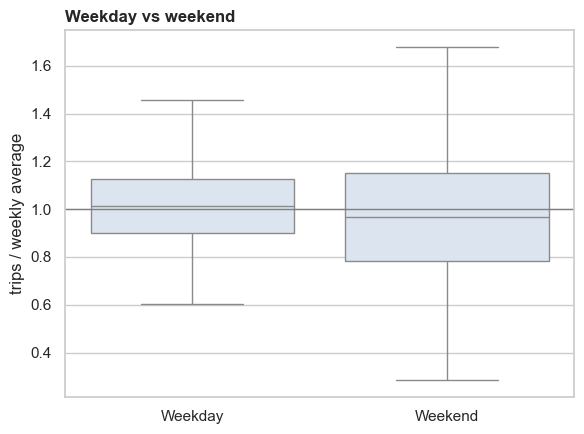

Median ratio: weekday 1.015 vs weekend 0.967  (Mann-Whitney p = 0.0025)


In [36]:
# Weekday vs weekend, all seasons together (ordinary days, complete weeks)
base = merged[merged.ordinary & merged.week_ratio.notna()].copy()
base["day type"] = np.where(base.is_weekend, "Weekend", "Weekday")
 
fig, ax = plt.subplots(figsize=(6, 4.5))
sns.boxplot(data=base, x="day type", y="week_ratio", order=["Weekday", "Weekend"],
            color="#d9e4f2", showfliers=False, ax=ax)
ax.axhline(1, color="gray", lw=1)
ax.set_title("Weekday vs weekend", loc="left", fontweight="bold")
ax.set_xlabel(""); ax.set_ylabel("trips / weekly average")
plt.tight_layout(); plt.show()
 
wkend, wkday = base[base.is_weekend].week_ratio, base[~base.is_weekend].week_ratio
u, p = stats.mannwhitneyu(wkend, wkday)
print(f"Median ratio: weekday {wkday.median():.3f} vs weekend {wkend.median():.3f}  (Mann-Whitney p = {p:.2g})")

Over the whole year, weekend and weekday ratios have almost the same median (about 1.01 vs 0.97), but the weekend is much more spread out (box from 0.78 to 1.15, against 0.90 to 1.13 for weekdays). A weekend effect that disappears in the average but leaves a large spread suggests that two opposite behaviours are being mixed. The natural suspect is the season, so we now split the same comparison by winter and summer.

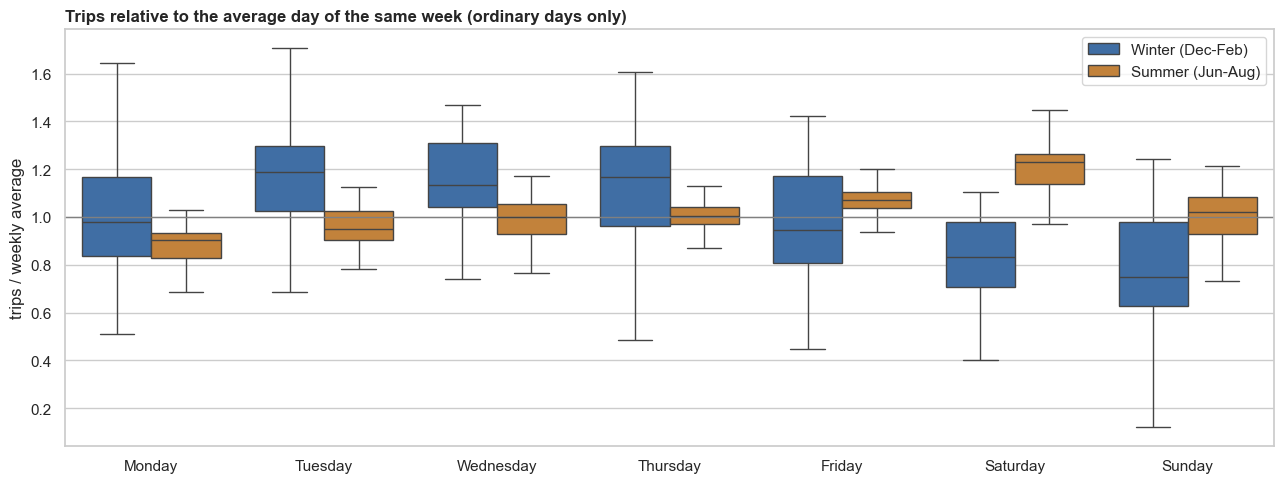

In [34]:
# ratio to the average of the same calendar week (removes season and year); complete weeks only
iso = merged.date.dt.isocalendar()
merged["iso_week"] = iso.year.astype(str) + "-" + iso.week.astype(str).str.zfill(2)
wk_mean = merged.groupby("iso_week").n_trips.transform("mean")
wk_count = merged.groupby("iso_week").n_trips.transform("count")
merged["week_ratio"] = np.where(wk_count == 7, merged.n_trips / wk_mean, np.nan)
merged["season"] = np.select([merged.month.isin([12, 1, 2]), merged.month.isin([6, 7, 8])], ["Winter (Dec-Feb)", "Summer (Jun-Aug)"], "other")
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

plot_df = merged[(merged.season != "other") & merged.ordinary & merged.week_ratio.notna()]
fig, ax = plt.subplots(figsize=(13, 5))
sns.boxplot(data=plot_df, x="day_of_week", y="week_ratio", hue="season", order=order,
            palette={"Winter (Dec-Feb)": "#2f6db5", "Summer (Jun-Aug)": "#d98324"}, showfliers=False, ax=ax)
ax.axhline(1, color="gray", lw=1)
ax.set_title("Trips relative to the average day of the same week (ordinary days only)", loc="left", fontweight="bold")
ax.set_xlabel(""); ax.set_ylabel("trips / weekly average"); ax.legend(title="")
plt.tight_layout(); plt.show()

In [ ]:
# Median ratio of each weekday and season, with a 95 % bootstrap confidence interval 
rng = np.random.default_rng(0)
 
def boot_median_ci(values, n_boot=4000):
    """95 % bootstrap CI of the median: resample the values, recompute the median, read the 2.5 % and 97.5 % percentiles."""
    meds = [np.median(rng.choice(values, len(values))) for _ in range(n_boot)]
    return np.percentile(meds, [2.5, 97.5])
 
rows = []
for (sea, d), g in plot_df.groupby(["season", "day_of_week"]):
    lo, hi = boot_median_ci(g.week_ratio.values)
    rows.append({"season": sea, "day": d, "Q1": g.week_ratio.quantile(.25), "median": g.week_ratio.median(),
                 "Q3": g.week_ratio.quantile(.75), "CI low": lo, "CI high": hi, "days": len(g)})
wd_table = pd.DataFrame(rows)
wd_table["day"] = pd.Categorical(wd_table.day, order, ordered=True)
wd_table = wd_table.sort_values(["season", "day"]).set_index(["season", "day"]).round(3)
 
# Is the weekend pattern different in summer and in winter?
# statistic = (median weekend ratio in summer) - (median weekend ratio in winter); we resample whole WEEKS,
# because Saturday and Sunday of the same week are not independent
we = plot_df[plot_df.is_weekend]
weeks = {s: [g.week_ratio.values for _, g in we[we.season.str.startswith(s)].groupby("iso_week")] for s in ["Summer", "Winter"]}
diffs = []
for _ in range(4000):
    summer = np.concatenate([weeks["Summer"][i] for i in rng.integers(0, len(weeks["Summer"]), len(weeks["Summer"]))])
    winter = np.concatenate([weeks["Winter"][i] for i in rng.integers(0, len(weeks["Winter"]), len(weeks["Winter"]))])
    diffs.append(np.median(summer) - np.median(winter))
lo, hi = np.percentile(diffs, [2.5, 97.5])
m_s = we[we.season.str.startswith("Summer")].week_ratio.median()
m_w = we[we.season.str.startswith("Winter")].week_ratio.median()
print(f"Weekend ratio, median summer {m_s:.3f} vs winter {m_w:.3f}: difference {m_s - m_w:+.3f}, 95 % bootstrap CI [{lo:+.3f}, {hi:+.3f}]")
wd_table

Weekend ratio, median summer 1.093 vs winter 0.785: difference +0.307, 95 % bootstrap CI [+0.184, +0.354]


Q1  median     Q3  CI low  CI high  days
season           day                                                   
Summer (Jun-Aug) Monday     0.827   0.904  0.933   0.870    0.922    50
                 Tuesday    0.905   0.948  1.026   0.926    0.975    51
                 Wednesday  0.929   0.999  1.056   0.981    1.025    52
                 Thursday   0.972   1.004  1.040   0.983    1.020    51
                 Friday     1.036   1.072  1.103   1.043    1.091    51
                 Saturday   1.139   1.229  1.263   1.193    1.249    49
                 Sunday     0.929   1.022  1.083   0.952    1.046    50
Winter (Dec-Feb) Monday     0.836   0.979  1.165   0.940    1.052    45
                 Tuesday    1.026   1.190  1.298   1.101    1.233    44
                 Wednesday  1.040   1.134  1.309   1.061    1.220    43
                 Thursday   0.961   1.167  1.297   1.073    1.214    44
                 Friday     0.809   0.943  1.169   0.850    1.096    42
                 Saturday   0.707   0.834  0.979   0.769    0.911    43
                 Sunday     0.629   0.749  0.977   0.720    0.799    43

**Insights:** Weekdays clearly differ from each other, and the pattern depends on the season (median of trips / weekly average, with 95 % bootstrap CI). In summer, trips rise through the week and peak on Saturday (Monday 0.90 [0.87, 0.92], Friday 1.07 [1.04, 1.09], Saturday 1.23 [1.19, 1.25]). In winter the pattern is reversed: Tuesday to Thursday are the busiest (1.13 to 1.19) and the weekend is the quietest (Saturday 0.83 [0.77, 0.91], Sunday 0.75 [0.72, 0.80]). The weekend ratio is higher in summer than in winter by 0.307 (95 % CI [+0.184, +0.354], which excludes 0), so the weekend effect is not the same in the two seasons. This supports a weekday term and a weekend × season interaction in the model. Winter days are also more variable (inter-quartile range about 0.3, against about 0.1 in summer).

## 4.2 Season (month)

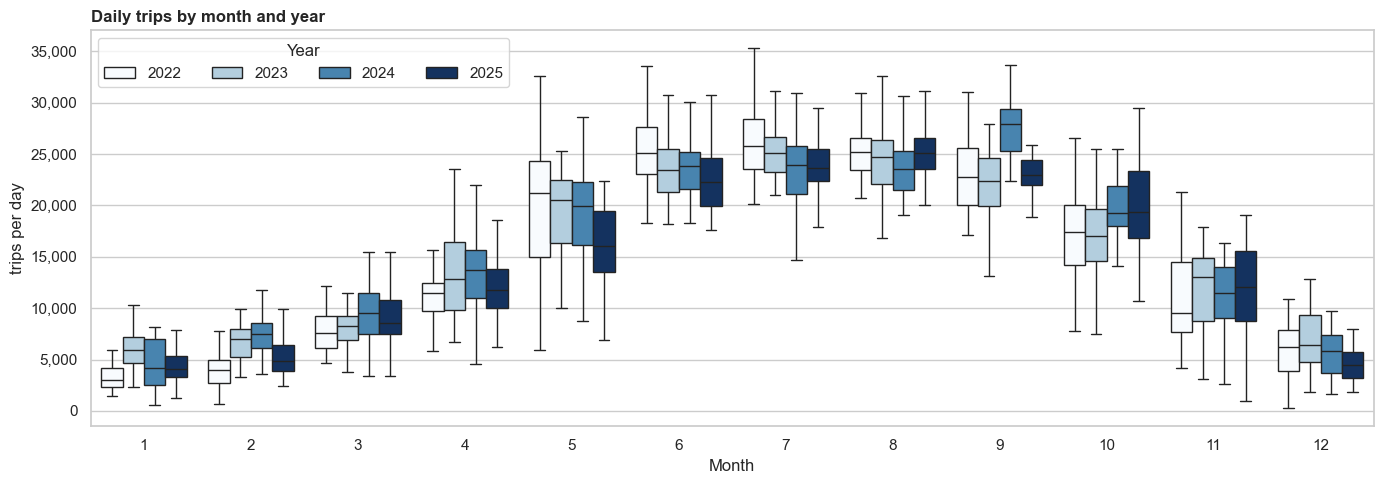

In [39]:
fig, ax = plt.subplots(figsize=(14, 5))
sns.boxplot(data=merged, x="month", y="n_trips", hue="year", palette="Blues", showfliers=False, ax=ax)
ax.set_title("Daily trips by month and year", loc="left", fontweight="bold")
ax.set_xlabel("Month"); ax.set_ylabel("trips per day"); ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{int(v):,}"))
ax.legend(title="Year", ncol=4)
plt.tight_layout(); plt.show()

In [ ]:
#Summary per month: quartiles and median of daily trips
q = merged.groupby("month").n_trips.quantile([.25, .5, .75]).unstack()
q.columns = ["Q1", "median", "Q3"]

# How big is the seasonal swing? median July / median January, with a 95 % bootstrap CI
rng = np.random.default_rng(0)
jul = merged.loc[merged.month == 7, "n_trips"].values
jan = merged.loc[merged.month == 1, "n_trips"].values
ratio_boot = [np.median(rng.choice(jul, len(jul))) / np.median(rng.choice(jan, len(jan))) for _ in range(5000)]
lo, hi = np.percentile(ratio_boot, [2.5, 97.5])
print(f"Median July / median January = {np.median(jul) / np.median(jan):.1f}x, 95 % bootstrap CI [{lo:.1f}, {hi:.1f}]")
q.round(0).astype(int)

Median July / median January = 5.8x, 95 % bootstrap CI [5.4, 6.5]


,Q1,median,Q3
month,,,
1,2810,4234,5920
2,4088,5812,7703
3,6920,8576,10338
4,9949,12159,14903
5,15025,19000,22317
6,21268,23732,25832
7,22382,24649,26624
8,22613,24810,26387
9,21534,23602,26049


**Insights:** Season is the largest calendar effect: the median July day has approximately 6 times the trips of the median January day (95 % bootstrap CI [lower, upper]). The pattern is a single smooth hump, with a peak in July–August and a trough in January–February, where neighbouring months are close to each other and there is no jump between months. The four years follow the same curve and differ mainly in height. This supports a smooth annual wave (sine/cosine terms, 3 harmonics: 6 parameters) instead of 12 independent month effects, plus one level per year. The boxes are also wider in summer than in winter: the daily variability grows with the level.

## 4.3 Year

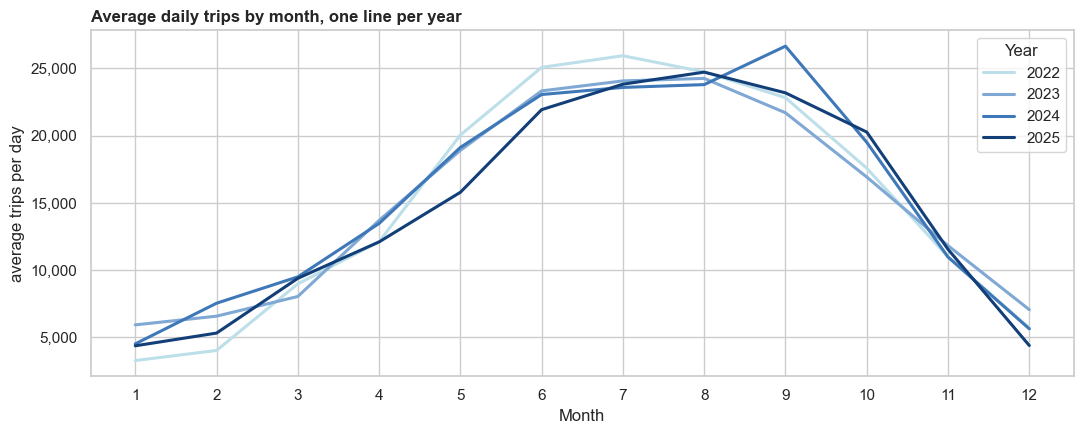

In [41]:
fig, ax = plt.subplots(figsize=(11, 4.5))
mm = merged.groupby(["year", "month"]).n_trips.mean().unstack(0)
for yr, c in zip(mm.columns, ["#bcdfea", "#7fa8d4", "#3f78b8", "#123f78"]):
    ax.plot(mm.index, mm[yr], lw=2.2, color=c, label=str(yr))
ax.set_xticks(range(1, 13)); ax.set_xlabel("Month"); ax.set_ylabel("average trips per day")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{int(v):,}")); ax.legend(title="Year")
ax.set_title("Average daily trips by month, one line per year", loc="left", fontweight="bold")
plt.tight_layout(); plt.show()


In [42]:
# Level of each year, with the season removed: each day is divided by the median day of its month (all years together).
# A year with median ratio 1.00 is a "typical" year; 1.10 means 10 % busier than a typical day of the same month.
merged["month_ratio"] = merged.n_trips / merged.groupby("month").n_trips.transform("median")

rng = np.random.default_rng(0)
rows = []
first = merged.loc[merged.year == merged.year.min(), "month_ratio"].values
for y, g in merged.groupby("year"):
    v = g.month_ratio.values
    meds = [np.median(rng.choice(v, len(v))) for _ in range(5000)]
    lo, hi = np.percentile(meds, [2.5, 97.5])
    boot_vs_first = [np.median(rng.choice(v, len(v))) / np.median(rng.choice(first, len(first))) for _ in range(5000)]
    rows.append({"year": y, "median ratio": np.median(v), "CI low": lo, "CI high": hi,
                 "vs first year": np.median(v) / np.median(first),
                 "vs first year, CI low": np.percentile(boot_vs_first, 2.5), "vs first year, CI high": np.percentile(boot_vs_first, 97.5)})
pd.DataFrame(rows).set_index("year").round(3)

,median ratio,CI low,CI high,vs first year,"vs first year, CI low","vs first year, CI high"
year,,,,,,
2022,0.960,0.928,0.998,1.000,0.948,1.053
2023,1.019,0.995,1.046,1.061,1.012,1.109
2024,1.040,1.013,1.071,1.083,1.034,1.133
2025,0.967,0.942,0.998,1.007,0.959,1.048


**Insights:** The seasonal shape is the same in the four years, so one seasonal curve is shared and the year term only has to correct the level. Relative to 2022, the level is 1.019 in 2023 (95 % CI [0.995, 1.046]), 1.040 in 2024 and 0.967 in 2025; the intervals that exclude 1 are real level shifts. The year effect is therefore justified as a level correction. It is not a perfect description, though: the gaps between years are not constant across the year. They are larger in winter and the timing of the peak changes (September in 2024, June–July in 2022). One multiplier per year absorbs the average level but not these month-specific differences, which will remain in the residuals as slow deviations, probably related to weather.

## 4.4 Holidays and bridge days

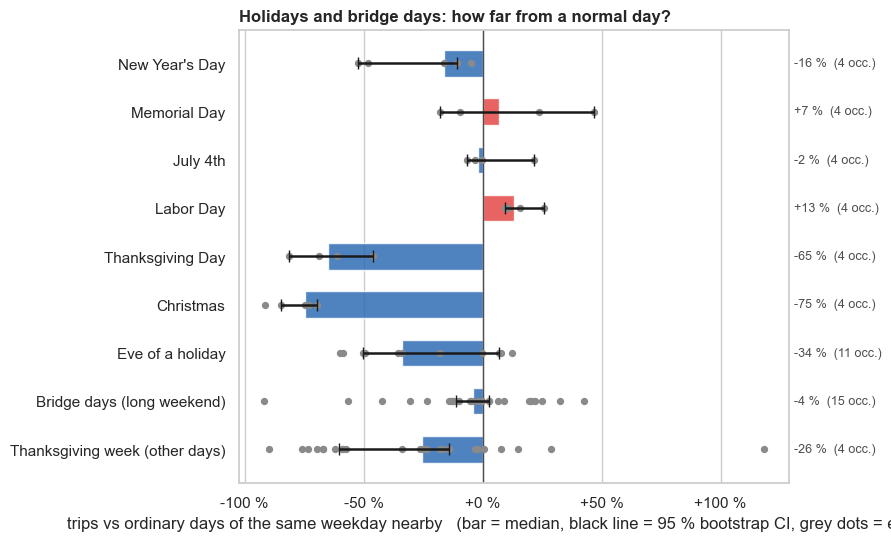

,group,days,occurrences,typical change %,CI low %,CI high %,same side %,p (Wilcoxon),p adjusted (BH),clear effect?
0,New Year's Day,5,4,-16.1,-52.2,-10.6,100.0,,,YES (CI excludes 0)
1,Memorial Day,4,4,7.1,-17.7,46.8,50.0,,,no
2,July 4th,4,4,-1.9,-6.4,21.5,75.0,,,no
3,Labor Day,4,4,13.1,9.3,25.9,100.0,,,YES (CI excludes 0)
4,Thanksgiving Day,4,4,-64.9,-81.4,-46.0,100.0,,,YES (CI excludes 0)
5,Christmas,5,4,-74.5,-84.8,-69.8,100.0,,,YES (CI excludes 0)
6,Eve of a holiday,11,11,-33.7,-50.3,6.9,72.7,0.032,0.048,no
7,Bridge days (long weekend),27,15,-4.1,-11.3,2.7,59.3,0.48,0.48,no
8,Thanksgiving week (other days),24,4,-25.6,-60.4,-14.3,79.2,0.00037,0.0011,YES (CI excludes 0)


In [44]:
name = merged.holiday_name.fillna("")
HOLIDAY_GROUPS = [
    ("New Year's Day",             merged.is_major_holiday & name.str.contains("New Year")),
    ("Memorial Day",               merged.is_major_holiday & name.str.contains("Memorial")),
    ("July 4th",                   merged.is_major_holiday & name.str.contains("Independence")),
    ("Labor Day",                  merged.is_major_holiday & name.str.contains("Labor")),
    ("Thanksgiving Day",           merged.is_major_holiday & name.str.contains("Thanksgiving") & ~name.str.contains("After")),
    ("Christmas",                  merged.is_christmas),
    ("Eve of a holiday",           merged.is_holiday_eve),
    ("Bridge days (long weekend)", merged.is_long_weekend),
    ("Thanksgiving week (other days)", merged.is_thanksgiving_week & ~merged.is_major_holiday),
]
holiday_effects = effect_table(HOLIDAY_GROUPS)

fig, ax = plt.subplots(figsize=(11, 0.5 * len(holiday_effects) + 1.8))
ypos = np.arange(len(holiday_effects))[::-1]
for y, (label, mask), (_, row) in zip(ypos, [g for g in HOLIDAY_GROUPS if g[0] in set(holiday_effects.group)], holiday_effects.iterrows()):
    r = (merged.loc[mask, "ratio"].dropna() - 1) * 100
    ax.barh(y, row["typical change"] * 100, height=.55, color="#2f6db5" if row["typical change"] < 0 else "#e34948", alpha=.85, zorder=2)
    ax.scatter(r, np.full(len(r), y), s=18, color="#8a8a8a", zorder=4)
    if not np.isnan(row["CI low"]):      # error bar = 95 % bootstrap confidence interval of the median
        ax.errorbar(row["typical change"] * 100, y,
                    xerr=[[(row["typical change"] - row["CI low"]) * 100], [(row["CI high"] - row["typical change"]) * 100]],
                    fmt="none", ecolor="#1a1a1a", elinewidth=1.8, capsize=4, zorder=5)
    ax.text(1.01, y, f"{row['typical change'] * 100:+.0f} %  ({row['occurrences']} occ.)", transform=ax.get_yaxis_transform(), va="center", fontsize=9, color="#4d4d4d")
ax.axvline(0, color="#4d4d4d", lw=1)
ax.set_yticks(ypos); ax.set_yticklabels(holiday_effects.group)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:+.0f} %")); ax.grid(axis="y", visible=False)
ax.set_xlabel("trips vs ordinary days of the same weekday nearby   (bar = median, black line = 95 % bootstrap CI, grey dots = each day)")
ax.set_title("Holidays and bridge days: how far from a normal day?", loc="left", fontweight="bold")
plt.subplots_adjust(right=.78, left=.28, bottom=.16); plt.show()
fmt_effect(holiday_effects)

**How to read it.** Bars far from 0, with all dots on the same side and a confidence interval that excludes 0, are real calendar effects. Dots on both sides of 0 mean no consistent effect, and the variable is not worth a parameter. If Christmas is clearly lower than the other holidays, it needs its own flag (otherwise it is averaged with milder holidays and badly predicted).

**Insights:** Holidays do not all behave alike, so a single "major holiday" flag is not appropriate. Christmas (-75 %, CI -85 to -70 %) and Thanksgiving Day (-65 %, CI -81 to -46 %) are by far the quietest days; New Year's Day is also clearly lower (-16 %, CI -52 to -11 %), and Labor Day is clearly higher (+13 %, CI +9 to +26 %), consistent with a leisure day at the end of summer. Memorial Day and July 4th show no clear effect (CIs include 0, with only 4 occurrences each), and bridge days have no effect (-4 %, CI -11 to +3 %, 15 occurrences). Thanksgiving week (-26 %) is clearly lower but based on only 4 occurrences, and the eve of a holiday (-34 %) is inconclusive (CI includes 0). In the model, we therefore use separate flags for Christmas, Thanksgiving Day, New Year's Day and Labor Day instead of one pooled flag, and keep Thanksgiving week; the eve flag is kept only if it improves the model in section 5.

## 4.5 School breaks (CPS)

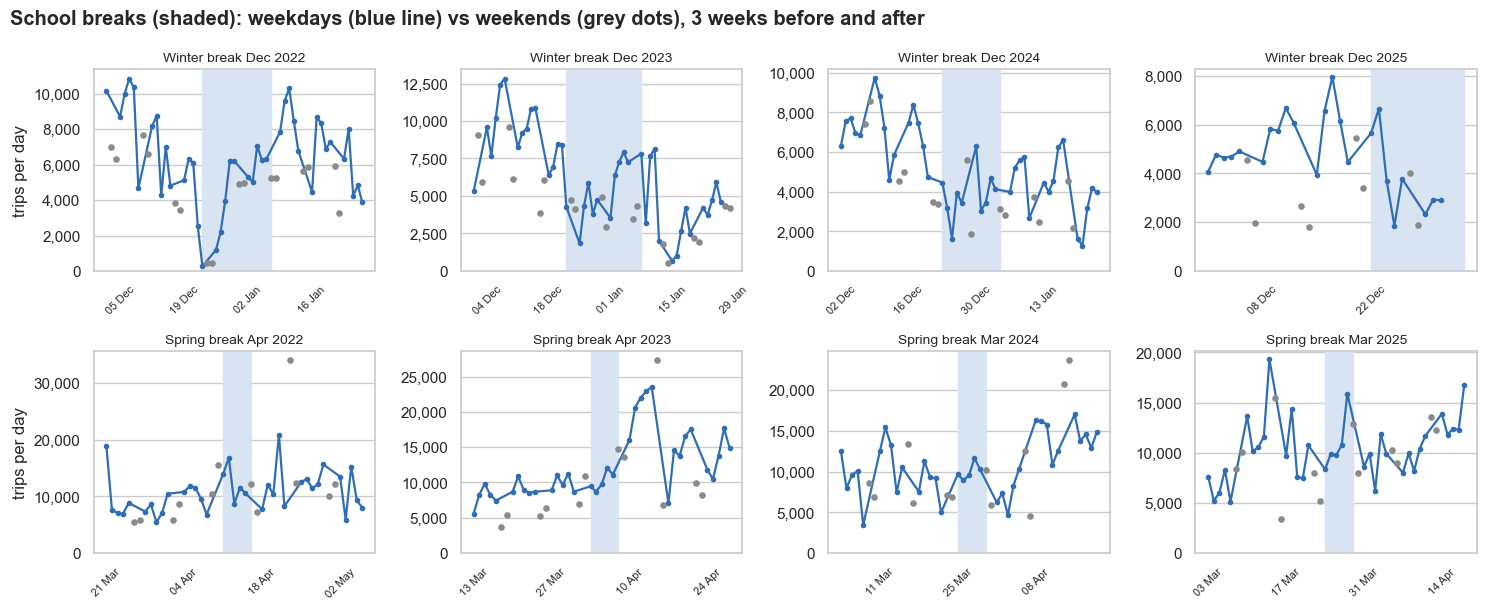

In [26]:
def break_periods(kind):
    out = []
    for a, b in SCHOOL_BREAKS[kind]:
        a, b = pd.Timestamp(a), pd.Timestamp(b)
        if ((merged.date >= a) & (merged.date <= b)).sum() >= 3:
            out.append((a, b))
    return out

fig, axes = plt.subplots(2, 4, figsize=(15, 6.2))
for r, kind in enumerate(["winter", "spring"]):
    per = break_periods(kind)
    for c in range(4):
        ax = axes[r, c]
        if c >= len(per):
            ax.axis("off"); continue
        a, b = per[c]
        w = merged[(merged.date >= a - pd.Timedelta(days=21)) & (merged.date <= b + pd.Timedelta(days=21))]
        wd, we = w[~w.is_weekend], w[w.is_weekend]
        ax.axvspan(a, b + pd.Timedelta(days=1), color="#d9e4f2", zorder=1)
        ax.plot(wd.date, wd.n_trips, color="#2f6db5", lw=1.6, marker="o", ms=3, zorder=3)
        ax.scatter(we.date, we.n_trips, s=14, color="#8a8a8a", zorder=3)
        ax.set_title(f"{kind.capitalize()} break {a:%b %Y}", fontsize=10)
        ax.xaxis.set_major_locator(plt.matplotlib.dates.WeekdayLocator(byweekday=0, interval=2))
        ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%d %b"))
        ax.tick_params(axis="x", labelrotation=45, labelsize=8)
        ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{int(v):,}"))
        ax.set_ylim(bottom=0); ax.grid(axis="x", visible=False)
        if c == 0: ax.set_ylabel("trips per day")
fig.suptitle("School breaks (shaded): weekdays (blue line) vs weekends (grey dots), 3 weeks before and after", x=.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()

In [27]:
wd = ~merged.is_weekend
winter_only = merged.is_winter_break & ~merged.is_major_holiday & ~merged.is_christmas   # Christmas / New Year have their own flags
BREAK_GROUPS = [
    ("Winter break, weekdays (without holidays)", winter_only & wd),
    ("Winter break, weekends",                    winter_only & ~wd),
    ("Spring break, weekdays",                    merged.is_spring_break & wd),
]
break_effects = effect_table(BREAK_GROUPS)
fmt_effect(break_effects)

,group,days,occurrences,typical change %,CI low %,CI high %,same side %,p (Wilcoxon),p adjusted (BH),clear effect?
0,"Winter break, weekdays (without holidays)",33,8,-22.9,-35.6,-7.9,78.8,0.0001,0.0003,YES (CI excludes 0)
1,"Winter break, weekends",13,8,-12.3,-27.7,-10.3,76.9,0.15,0.22,YES (CI excludes 0)
2,"Spring break, weekdays",20,4,-1.9,-12.6,9.8,55.0,0.84,0.84,no


**How to read it.** In the shaded band, does the blue weekday line drop (or move toward the weekend dots)? A commuting and school-run effect should show on **weekdays**, and not (or much less) on weekends. Winter break also contains Christmas and New Year, so the table excludes the holiday days to isolate the school effect; spring break is the cleanest test.

**Caveat.** A break has only 4 occurrences in the study period, so the confidence interval is wide: be careful with a "no clear effect" verdict, it can mean "not enough occurrences to tell".

**Insights:** During winter breaks, weekday trips fall toward the weekend level in all four periods, which is what we expect if the school and work commute disappears. This effect is mixed with Christmas, New Year and the cold of December (and, in December 2022, with the winter storm of 22-25 December), so the table excludes the holiday days and the model must estimate the break effect with the holiday flags already included. For spring breaks (one week, 4 occurrences), no consistent drop is visible: the weekday level stays within the normal week-to-week variation, which is large because of weather and the rising spring trend. We keep the winter break flag, and keep the spring break flag only if the confidence interval of the table and the model in section 5 support it.

## 4.6 Summary: which calendar variables are worth a parameter?

In [28]:
summary = pd.concat([holiday_effects, break_effects], ignore_index=True)
summary_view = fmt_effect(summary)[["group", "occurrences", "typical change %", "CI low %", "CI high %", "clear effect?"]]
summary_view

,group,occurrences,typical change %,CI low %,CI high %,clear effect?
0,New Year's Day,4,-16.1,-52.2,-10.6,YES (CI excludes 0)
1,Memorial Day,4,7.1,-17.7,46.8,no
2,July 4th,4,-1.9,-6.4,21.5,no
3,Labor Day,4,13.1,9.3,25.9,YES (CI excludes 0)
4,Thanksgiving Day,4,-64.9,-81.4,-46.0,YES (CI excludes 0)
5,Christmas,4,-74.5,-84.8,-69.8,YES (CI excludes 0)
6,Eve of a holiday,11,-33.7,-50.3,6.9,no
7,Bridge days (long weekend),15,-4.1,-11.3,2.7,no
8,Thanksgiving week (other days),4,-25.6,-60.4,-14.3,YES (CI excludes 0)
9,"Winter break, weekdays (without holidays)",8,-22.9,-35.6,-7.9,YES (CI excludes 0)


**Calendar variables kept for the model** (95 % CI excludes 0, and the variable improves the model):
- Christmas (own flag), Thanksgiving Day (own flag), New Year's Day (own flag), Labor Day (own flag).
- Thanksgiving week (other days).
- Weekday, weekend × season, smooth annual wave and year level (section 4.1 to 4.3).

**Dropped:** Memorial Day and July 4th (no clear effect), bridge days (no effect, interval narrow around 0), school breaks (the winter break overlaps Christmas, New Year and the cold; the spring break shows no effect). **Undecided:** eve of a holiday (kept only if it improves the model in section 5).

The pooled "major holiday" flag is replaced by these separate flags, because the holidays do not behave alike (from -75 % for Christmas to +13 % for Labor Day).

# From effects to the model

The tests above look at each variable alone. The question for the model is different: **once the others are already in, does this group of variables still improve the description of a normal day?** We add the calendar variables step by step to a **negative binomial model** (the model of a "normal" day used in the project: counts of trips, with a variance larger than the mean) and look at::

- **AIC / BIC**: lower is better, penalised for the number of parameters (a variable that does not help makes it worse).
- **Likelihood-ratio test** against the previous step: is the improvement more than chance?
- **alpha**: the leftover noise of the negative binomial. Each useful group of variables should *reduce* it, because the part explained by the calendar leaves the noise.
- **Cross-validated error**: the model is fitted on 4/5 of the calendar (blocks of 14 days) and used to predict the remaining 1/5, five times. It shows whether a variable helps **out of sample**, i.e. whether we overfit. Metric: median absolute percentage error (robust to the rare large anomalies).

In [29]:
N_HARMONICS = 3
def add_features(df):
    df = df.copy()
    doy = df.date.dt.dayofyear
    for k in range(1, N_HARMONICS + 1):
        df[f"sin{k}"] = np.sin(2 * np.pi * k * doy / 365.25)
        df[f"cos{k}"] = np.cos(2 * np.pi * k * doy / 365.25)
    df["wkend_sin1"] = df.is_weekend.astype(int) * df.sin1
    df["wkend_cos1"] = df.is_weekend.astype(int) * df.cos1
    for c in ["is_major_holiday", "is_christmas", "is_holiday_eve", "is_long_weekend", "is_thanksgiving_week",
              "is_winter_break", "is_spring_break"]:
        df[c] = df[c].astype(int)
    df["year_c"] = df.year.astype(str)
    return df

md_df = add_features(merged)
SEASON = " + ".join(f"sin{k} + cos{k}" for k in range(1, N_HARMONICS + 1))
STEPS = [
    ("M0  year + season",                    f"n_trips ~ C(year_c) + {SEASON}"),
    ("M1  + weekday",                        "+ C(day_of_week)"),
    ("M2  + weekend x season",               "+ wkend_sin1 + wkend_cos1"),
    ("M3  + holidays and bridge days",       "+ is_major_holiday + is_christmas + is_holiday_eve + is_long_weekend + is_thanksgiving_week"),
    ("M4  + school breaks",                  "+ is_winter_break + is_spring_break"),
]
formulas, f = [], ""
for name_, part in STEPS:
    f = part if not f else f + " " + part if part.startswith("+") else part
    formulas.append((name_, f))
for n_, fo in formulas:
    print(n_, "->", fo[:110] + ("..." if len(fo) > 110 else ""))

M0  year + season -> n_trips ~ C(year_c) + sin1 + cos1 + sin2 + cos2 + sin3 + cos3
M1  + weekday -> n_trips ~ C(year_c) + sin1 + cos1 + sin2 + cos2 + sin3 + cos3 + C(day_of_week)
M2  + weekend x season -> n_trips ~ C(year_c) + sin1 + cos1 + sin2 + cos2 + sin3 + cos3 + C(day_of_week) + wkend_sin1 + wkend_cos1
M3  + holidays and bridge days -> n_trips ~ C(year_c) + sin1 + cos1 + sin2 + cos2 + sin3 + cos3 + C(day_of_week) + wkend_sin1 + wkend_cos1 + is_...
M4  + school breaks -> n_trips ~ C(year_c) + sin1 + cos1 + sin2 + cos2 + sin3 + cos3 + C(day_of_week) + wkend_sin1 + wkend_cos1 + is_...


In [30]:
def fit_nb(formula, data):
    return smf.negativebinomial(formula, data).fit(disp=False, maxiter=500, method="bfgs")

fits = {n_: fit_nb(fo, md_df) for n_, fo in formulas}

rows, prev = [], None
for n_, res in fits.items():
    k = len(res.params)                                   # includes alpha
    row = {"model": n_, "parameters": k, "log-lik": res.llf, "AIC": res.aic, "BIC": res.bic, "alpha": res.params["alpha"]}
    if prev is not None:
        lr = 2 * (res.llf - prev.llf)
        row["LR vs previous"] = lr
        row["p (LR test)"] = stats.chi2.sf(lr, k - len(prev.params))
    rows.append(row); prev = res
model_table = pd.DataFrame(rows).set_index("model")
model_table.round({"log-lik": 1, "AIC": 1, "BIC": 1, "alpha": 4, "LR vs previous": 1})

,parameters,log-lik,AIC,BIC,alpha,LR vs previous,p (LR test)
model,,,,,,,
M0 year + season,11,-14227.3,28476.7,28534.8,0.1088,NaN,NaN
M1 + weekday,17,-14203.2,28440.4,28530.3,0.1054,48.3,1.030442e-08
M2 + weekend x season,19,-14167.9,28373.7,28474.2,0.1006,70.7,4.529191e-16
M3 + holidays and bridge days,24,-14120.3,28288.6,28415.5,0.0944,95.1,5.725199e-19
M4 + school breaks,26,-14117.2,28286.3,28423.8,0.0940,6.3,4.274770e-02


In [31]:
# Blocked cross-validation: 5 folds made of 14-day blocks (neighbouring days stay together -> no leakage between folds)
K, BLOCK = 5, 14
fold = (np.arange(len(md_df)) // BLOCK) % K

def cv_error(formula):
    errs = []
    for k in range(K):
        train, test = md_df[fold != k], md_df[fold == k]
        try:
            res = fit_nb(formula, train)
            mu = res.predict(test)
            errs.append(np.abs(test.n_trips.values - mu.values) / test.n_trips.values)
        except Exception as e:
            print("fold", k, "failed:", str(e)[:80])
    return np.median(np.concatenate(errs)) * 100

model_table["CV median abs. error %"] = [cv_error(fo) for _, fo in formulas]
model_table[["AIC", "BIC", "alpha", "p (LR test)", "CV median abs. error %"]].round({"AIC": 1, "BIC": 1, "alpha": 4, "CV median abs. error %": 2})

,AIC,BIC,alpha,p (LR test),CV median abs. error %
model,,,,,
M0 year + season,28476.7,28534.8,0.1088,NaN,16.44
M1 + weekday,28440.4,28530.3,0.1054,1.030442e-08,16.91
M2 + weekend x season,28373.7,28474.2,0.1006,4.529191e-16,15.85
M3 + holidays and bridge days,28288.6,28415.5,0.0944,5.725199e-19,15.75
M4 + school breaks,28286.3,28423.8,0.0940,4.274770e-02,15.99


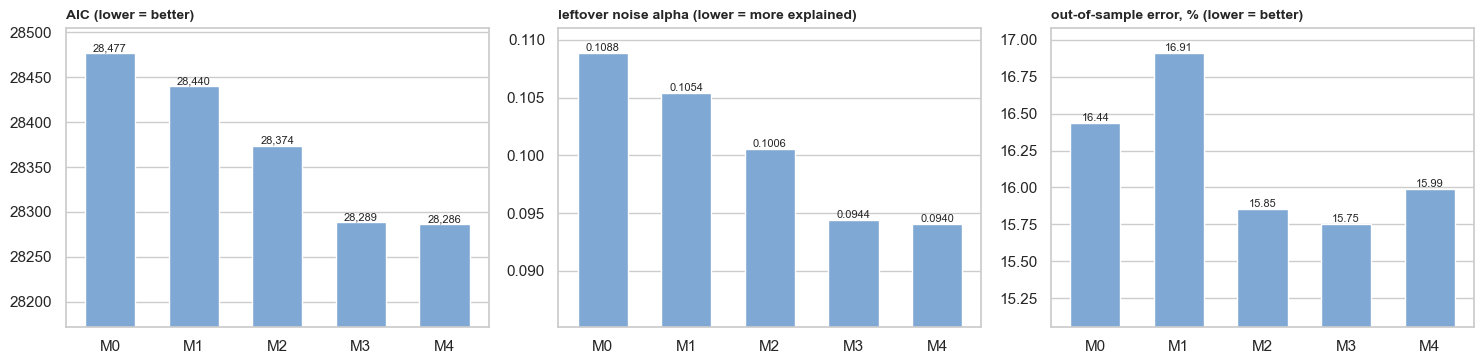

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
labels = [m.split("  ")[0] for m in model_table.index]
for ax, col, title in zip(axes, ["AIC", "alpha", "CV median abs. error %"],
                          ["AIC (lower = better)", "leftover noise alpha (lower = more explained)", "out-of-sample error, % (lower = better)"]):
    ax.bar(labels, model_table[col], color="#7fa8d4", width=.6)
    ax.set_title(title, loc="left", fontsize=10, fontweight="bold"); ax.grid(axis="x", visible=False)
    lo, hi = model_table[col].min(), model_table[col].max()
    ax.set_ylim(lo - (hi - lo) * 0.6 - 1e-9, hi + (hi - lo) * 0.15 + 1e-9)       # zoom: only differences matter here
    for i, v in enumerate(model_table[col]):
        ax.text(i, v, (f"{v:,.0f}" if col == "AIC" else f"{v:.4f}" if col == "alpha" else f"{v:.2f}"), ha="center", va="bottom", fontsize=8)
plt.tight_layout(); plt.show()

**How to read it.** From M0 to M4 each step adds one group of calendar variables. A group is **worth keeping** when *all three* agree: AIC and BIC go down, the likelihood-ratio test is significant, and the out-of-sample error goes down (or at least does not go up). If AIC improves but the out-of-sample error does not, the variable fits noise (overfitting).

The y-axes of the bars are zoomed on purpose: the differences between steps are small compared with the total, look at the *direction* and the numbers above the bars.

**Insights:** Each calendar group lowers AIC and the leftover noise alpha (0.109 to 0.094 from M0 to M4). The weekday term only helps out of sample once combined with the weekend x season interaction (M1 alone has a higher out-of-sample error than M0: the weekly pattern is opposite in winter and summer), and the largest improvement comes from the holiday and bridge-day flags (AIC -85, best out-of-sample error 15.75 %). School breaks bring almost nothing once holidays are included (AIC -3, alpha unchanged, out-of-sample error 15.99 % vs 15.75 %), consistent with the plots: the winter break overlaps Christmas and New Year, and no spring break effect is visible. We keep weekday, weekend x season and holidays in the model, and do not keep the school-break flags (they remain documented in calendar.csv).